<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/04_Sentimiento_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Análisis de sentimiento con Naive Bayes</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Teorema de Bayes</span>](#teorema-de-bayes)
- [<span style="color: #005C99;">Datos y preprocesamiento</span>](#datos-y-preprocesamiento)
- [<span style="color: #005C99;">Naive Bayes multinomial</span>](#naive-bayes-multinomial)
- [<span style="color: #005C99;">Suavizado de Laplace</span>](#suavizado-de-laplace)
- [<span style="color: #005C99;">Entrenamiento desde cero</span>](#entrenamiento-desde-cero)
- [<span style="color: #005C99;">Evaluación e interpretación</span>](#evaluacion-e-interpretacion)
- [<span style="color: #005C99;">Naive Bayes con scikit-learn</span>](#naive-bayes-con-scikit-learn)
- [<span style="color: #005C99;">Comparación con regresión logística</span>](#comparacion-con-regresion-logistica)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import string
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import twitter_samples, stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import TweetTokenizer

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", message="Glyph")

for recurso in ["twitter_samples", "stopwords"]:
    nltk.download(recurso, quiet=True)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En el cuaderno anterior resolvimos el análisis de sentimiento con un modelo **discriminativo**: la regresión logística modela directamente $P(y \mid \mathbf{x})$.

**Naive Bayes** es un modelo **generativo**: modela cómo se generan los datos de cada clase, $P(\mathbf{x} \mid y)$, y usa el teorema de Bayes para invertir la probabilidad. Es uno de los clasificadores de texto más antiguos y sigue siendo una línea base excelente:

- Se entrena en **una sola pasada** por los datos (solo hay que contar).
- Funciona bien con **pocos datos** y vocabularios grandes.
- Es fácil de interpretar.

Usaremos el mismo conjunto de tweets y el mismo preprocesamiento para poder comparar ambos modelos de forma justa.

<a id="teorema-de-bayes"></a>
<h2 style="color: #007ACC;">Teorema de Bayes</h2>

Para dos eventos $A$ y $B$:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Aplicado a clasificación de documentos, con $c$ una clase y $d$ un documento:

$$\underbrace{P(c \mid d)}_{\text{posterior}} = \frac{\overbrace{P(d \mid c)}^{\text{verosimilitud}} \; \overbrace{P(c)}^{\text{a priori}}}{\underbrace{P(d)}_{\text{evidencia}}}$$

Para clasificar elegimos la clase con mayor probabilidad posterior. Como $P(d)$ es igual para todas las clases, podemos ignorarla:

$$\hat{c} = \arg\max_{c} \; P(d \mid c)\, P(c)$$

**Ejemplo:** el 20 % de los tweets de un corpus son negativos y la palabra *sad* aparece en el 15 % de los negativos y en el 1 % de los positivos. Si un tweet contiene *sad*, ¿cuál es la probabilidad de que sea negativo?

In [3]:
p_neg = 0.20
p_sad_dado_neg, p_sad_dado_pos = 0.15, 0.01

p_sad = p_sad_dado_neg * p_neg + p_sad_dado_pos * (1 - p_neg)  # probabilidad total
p_neg_dado_sad = p_sad_dado_neg * p_neg / p_sad
print(f"P(negativo | 'sad') = {p_neg_dado_sad:.3f}")

P(negativo | 'sad') = 0.789


Aunque los negativos son minoría, ver *sad* hace que la probabilidad de negativo suba del 20 % a casi el 79 %.

<a id="datos-y-preprocesamiento"></a>
<h2 style="color: #007ACC;">Datos y preprocesamiento</h2>

Repetimos exactamente la división y el preprocesamiento del cuaderno 03 (misma semilla).

In [4]:
positivos = twitter_samples.strings("positive_tweets.json")
negativos = twitter_samples.strings("negative_tweets.json")
tweets = positivos + negativos
etiquetas = np.array([1] * len(positivos) + [0] * len(negativos))

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    tweets, etiquetas, test_size=0.2, stratify=etiquetas, random_state=SEED
)

STOP_EN = set(stopwords.words("english"))
stemmer = PorterStemmer()
tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)


def procesar_tweet(tweet):
    tweet = re.sub(r"^RT[\s]+", "", tweet)
    tweet = re.sub(r"https?://\S+", "", tweet)
    tweet = re.sub(r"#", "", tweet)
    tokens = tokenizer.tokenize(tweet)
    return [stemmer.stem(t) for t in tokens if t not in STOP_EN and t not in string.punctuation]


X_train_tok = [procesar_tweet(t) for t in X_train_txt]
X_test_tok = [procesar_tweet(t) for t in X_test_txt]
print(f"Entrenamiento: {len(X_train_tok)} | Prueba: {len(X_test_tok)}")

Entrenamiento: 8000 | Prueba: 2000


<a id="naive-bayes-multinomial"></a>
<h2 style="color: #007ACC;">Naive Bayes multinomial</h2>

Calcular $P(d \mid c)$ directamente es imposible: casi ningún documento se repite exactamente. Naive Bayes hace dos supuestos simplificadores:

1. **Bolsa de palabras:** el orden de las palabras no importa.
2. **Independencia condicional ("ingenua"):** dadas la clase, las palabras son independientes entre sí.

$$P(d \mid c) = P(w_1, \dots, w_n \mid c) \approx \prod_{i=1}^{n} P(w_i \mid c)$$

El supuesto es claramente falso (*San* y *Francisco* no son independientes), pero en la práctica el clasificador funciona sorprendentemente bien: para decidir solo necesitamos que la **clase con mayor puntaje** sea la correcta, no que las probabilidades sean exactas.

<h3 style="color: #007ACC;">Trabajar en espacio logarítmico</h3>

Multiplicar cientos de probabilidades pequeñas produce números tan cercanos a cero que la computadora los redondea a 0 (*underflow*). Por eso usamos logaritmos, que convierten productos en sumas. Para clasificación binaria definimos:

- **Log prior:** $\displaystyle \log \frac{P(\text{pos})}{P(\text{neg})}$
- **Razón de log-verosimilitud** de cada palabra: $\displaystyle \lambda(w) = \log \frac{P(w \mid \text{pos})}{P(w \mid \text{neg})}$

Y el puntaje de un tweet es:

$$\text{puntaje}(d) = \log \frac{P(\text{pos})}{P(\text{neg})} + \sum_{i=1}^{n} \lambda(w_i)$$

Si el puntaje es mayor que 0, predecimos positivo. Cada palabra "vota" con su $\lambda(w)$: positivo si es más típica de tweets positivos, negativo en caso contrario, y cercano a cero si es neutra.

In [5]:
# Demostración del underflow
probs = np.full(500, 0.01)
print("Producto directo:  ", np.prod(probs))
print("Suma de logaritmos:", np.sum(np.log(probs)))

Producto directo:   0.0
Suma de logaritmos: -2302.585092994045


<a id="suavizado-de-laplace"></a>
<h2 style="color: #007ACC;">Suavizado de Laplace</h2>

La estimación natural de $P(w \mid c)$ es la frecuencia relativa:

$$P(w \mid c) = \frac{\text{freq}(w, c)}{N_c}$$

donde $N_c$ es el número total de palabras en los documentos de la clase $c$. Pero si una palabra **nunca** apareció en tweets positivos, $P(w \mid \text{pos}) = 0$ y todo el producto se anula: una sola palabra vetaría la clase. Además $\log 0 = -\infty$.

El **suavizado de Laplace** (o "suma uno") añade una cuenta ficticia a cada palabra del vocabulario $V$:

$$P(w \mid c) = \frac{\text{freq}(w, c) + 1}{N_c + |V|}$$

Así ninguna probabilidad es cero y las probabilidades siguen sumando 1 sobre el vocabulario. Con un hiperparámetro $\alpha$ en lugar de 1 se obtiene el **suavizado aditivo** general.

<a id="entrenamiento-desde-cero"></a>
<h2 style="color: #007ACC;">Entrenamiento desde cero</h2>

In [6]:
def entrenar_naive_bayes(tokens_por_tweet, y, alpha=1.0):
    freqs = Counter()
    for tokens, etiqueta in zip(tokens_por_tweet, y):
        for palabra in tokens:
            freqs[(palabra, int(etiqueta))] += 1

    vocab = {palabra for palabra, _ in freqs}
    n_pos = sum(c for (_, et), c in freqs.items() if et == 1)  # total de palabras en tweets positivos
    n_neg = sum(c for (_, et), c in freqs.items() if et == 0)

    logprior = np.log(np.mean(y)) - np.log(1 - np.mean(y))
    loglikelihood = {}
    for w in vocab:
        p_w_pos = (freqs[(w, 1)] + alpha) / (n_pos + alpha * len(vocab))
        p_w_neg = (freqs[(w, 0)] + alpha) / (n_neg + alpha * len(vocab))
        loglikelihood[w] = np.log(p_w_pos / p_w_neg)
    return logprior, loglikelihood, freqs


inicio = time.perf_counter()
logprior, loglikelihood, freqs = entrenar_naive_bayes(X_train_tok, y_train)
print(f"Entrenado en {time.perf_counter() - inicio:.3f} s")
print(f"Log prior: {logprior:.4f} (clases balanceadas -> cercano a 0)")
print(f"Palabras en el vocabulario: {len(loglikelihood)}")

Entrenado en 0.011 s
Log prior: 0.0000 (clases balanceadas -> cercano a 0)
Palabras en el vocabulario: 9153


In [7]:
def puntaje_nb(tokens, logprior, loglikelihood):
    # Las palabras desconocidas se ignoran (no aportan evidencia)
    return logprior + sum(loglikelihood.get(w, 0.0) for w in tokens)


def predecir_nb(lista_tokens, logprior, loglikelihood):
    return np.array([int(puntaje_nb(t, logprior, loglikelihood) > 0) for t in lista_tokens])


for frase in ["I am happy because I am learning :)", "I am sad, this is terrible", "The movie was not good"]:
    tokens = procesar_tweet(frase)
    print(f"{frase:<38} tokens={tokens} puntaje={puntaje_nb(tokens, logprior, loglikelihood):+.2f}")

I am happy because I am learning :)    tokens=['happi', 'learn', ':)'] puntaje=+9.80
I am sad, this is terrible             tokens=['sad', 'terribl'] puntaje=-4.16
The movie was not good                 tokens=['movi', 'good'] puntaje=+1.06


<a id="evaluacion-e-interpretacion"></a>
<h2 style="color: #007ACC;">Evaluación e interpretación</h2>

Exactitud Naive Bayes (desde cero): 0.9965

              precision    recall  f1-score   support

    negativo       1.00      1.00      1.00      1000
    positivo       1.00      1.00      1.00      1000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



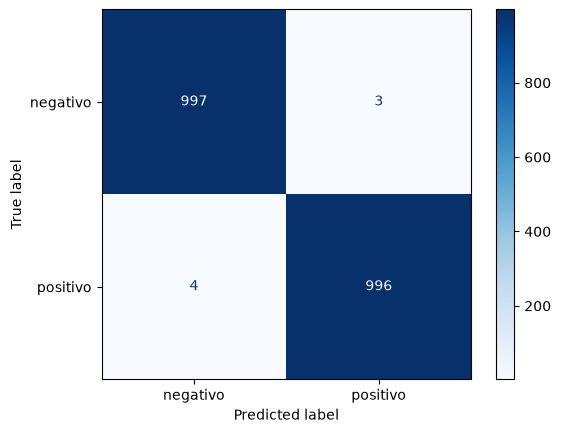

In [8]:
y_pred_nb = predecir_nb(X_test_tok, logprior, loglikelihood)
print(f"Exactitud Naive Bayes (desde cero): {accuracy_score(y_test, y_pred_nb):.4f}\n")
print(classification_report(y_test, y_pred_nb, target_names=["negativo", "positivo"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, display_labels=["negativo", "positivo"], cmap="Blues")
plt.show()

La razón $\lambda(w)$ nos dice cuánto "empuja" cada palabra hacia una clase. Veamos las palabras más polarizadas entre las que aparecen al menos 20 veces:

In [9]:
tabla = pd.DataFrame(
    [(w, freqs[(w, 1)], freqs[(w, 0)], ll) for w, ll in loglikelihood.items()],
    columns=["palabra", "frec_pos", "frec_neg", "lambda"],
)
frecuentes = tabla[tabla.frec_pos + tabla.frec_neg >= 20].sort_values("lambda")

pd.concat([frecuentes.head(8), frecuentes.tail(8)]).reset_index(drop=True)

,palabra,frec_pos,frec_neg,lambda
0,:(,0,3646,-8.217689
1,:-(,0,409,-6.032186
2,♛,0,180,-5.214526
3,》,0,180,-5.214526
4,>:(,0,40,-3.729601
5,beli̇ev,0,30,-3.450016
6,ｓｅｅ,0,30,-3.450016
7,ｍｅ,0,30,-3.450016
8,;),22,0,3.119465
9,fback,26,0,3.279808


Además de los emoticones aparecen tokens extraños (`♛`, `》`, `justi̇n`, `beli̇ev`) con exactamente la misma frecuencia: provienen de un mismo tweet de spam repetido decenas de veces en la clase negativa. Las duplicaciones inflan la importancia de esas palabras, y deduplicar el corpus es parte de un buen preprocesamiento.

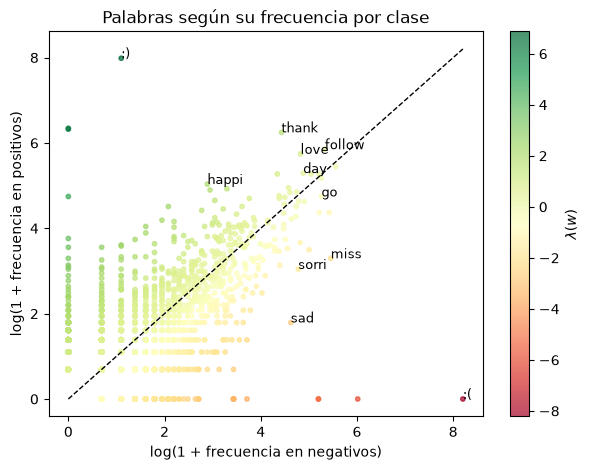

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(np.log1p(tabla.frec_neg), np.log1p(tabla.frec_pos), c=tabla["lambda"], cmap="RdYlGn", s=10, alpha=0.7)
for w in ["happi", "love", "thank", "sad", "miss", "sorri", "follow", "day", "go", ":)", ":("]:
    fila = tabla[tabla.palabra == w].iloc[0]
    plt.annotate(w, (np.log1p(fila.frec_neg), np.log1p(fila.frec_pos)), fontsize=9)
lim = np.log1p(tabla[["frec_pos", "frec_neg"]].values.max())
plt.plot([0, lim], [0, lim], "k--", lw=1)
plt.colorbar(label=r"$\lambda(w)$")
plt.xlabel("log(1 + frecuencia en negativos)")
plt.ylabel("log(1 + frecuencia en positivos)")
plt.title("Palabras según su frecuencia por clase")
plt.show()

Las palabras sobre la diagonal aparecen por igual en ambas clases ($\lambda \approx 0$, neutras). Las alejadas de ella son las que más información aportan. Igual que en el cuaderno anterior, los emoticones `:)` y `:(` son las más extremas.

<a id="naive-bayes-con-scikit-learn"></a>
<h2 style="color: #007ACC;">Naive Bayes con scikit-learn</h2>

`MultinomialNB` de scikit-learn implementa el mismo modelo (con `alpha=1` es suavizado de Laplace). Usando `CountVectorizer` con nuestro tokenizador deberíamos obtener **exactamente las mismas predicciones**: es una buena forma de verificar nuestra implementación.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

nb_sk = make_pipeline(
    CountVectorizer(tokenizer=procesar_tweet, lowercase=False, token_pattern=None),
    MultinomialNB(alpha=1.0),
)
nb_sk.fit(X_train_txt, y_train)
y_pred_sk = nb_sk.predict(X_test_txt)

print(f"Exactitud MultinomialNB: {accuracy_score(y_test, y_pred_sk):.4f}")
print(f"Coincidencia con nuestra implementación: {np.mean(y_pred_sk == y_pred_nb):.2%}")

Exactitud MultinomialNB: 0.9965
Coincidencia con nuestra implementación: 100.00%


<a id="comparacion-con-regresion-logistica"></a>
<h2 style="color: #007ACC;">Comparación con regresión logística</h2>

Comparemos Naive Bayes y regresión logística en igualdad de condiciones, con y sin emoticones (recuerda del cuaderno 03 que las etiquetas de este corpus se derivaron de los emoticones). Medimos también cómo cambia el desempeño con **pocos datos de entrenamiento**, donde se suele decir que Naive Bayes destaca.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


def procesar_sin_emoticones(tweet):
    return [t for t in procesar_tweet(tweet) if re.search(r"[a-z]", t)]


def crear_modelo(nombre, tokenizador):
    if nombre == "Naive Bayes":
        return make_pipeline(CountVectorizer(tokenizer=tokenizador, lowercase=False, token_pattern=None),
                             MultinomialNB(alpha=1.0))
    return make_pipeline(TfidfVectorizer(tokenizer=tokenizador, lowercase=False, token_pattern=None),
                         LogisticRegression(max_iter=1000))


resultados = []
rng = np.random.default_rng(SEED)
for tam in [100, 500, 2000, len(X_train_txt)]:
    idx = rng.choice(len(X_train_txt), size=tam, replace=False)
    X_sub, y_sub = [X_train_txt[i] for i in idx], y_train[idx]
    for nombre in ["Naive Bayes", "Regresión logística"]:
        for emo, tok in [("con emoticones", procesar_tweet), ("sin emoticones", procesar_sin_emoticones)]:
            modelo = crear_modelo(nombre, tok).fit(X_sub, y_sub)
            pred = modelo.predict(X_test_txt)
            resultados.append({"n_train": tam, "modelo": nombre, "datos": emo, "f1": f1_score(y_test, pred)})

resultados = pd.DataFrame(resultados)
resultados.pivot_table(index="n_train", columns=["datos", "modelo"], values="f1").round(3)

datos   con emoticones                     sin emoticones                    
modelo     Naive Bayes Regresión logística    Naive Bayes Regresión logística
n_train                                                                      
100              0.987               0.981          0.632               0.556
500              0.993               0.996          0.717               0.709
2000             0.996               0.998          0.742               0.738
8000             0.996               0.997          0.773               0.767

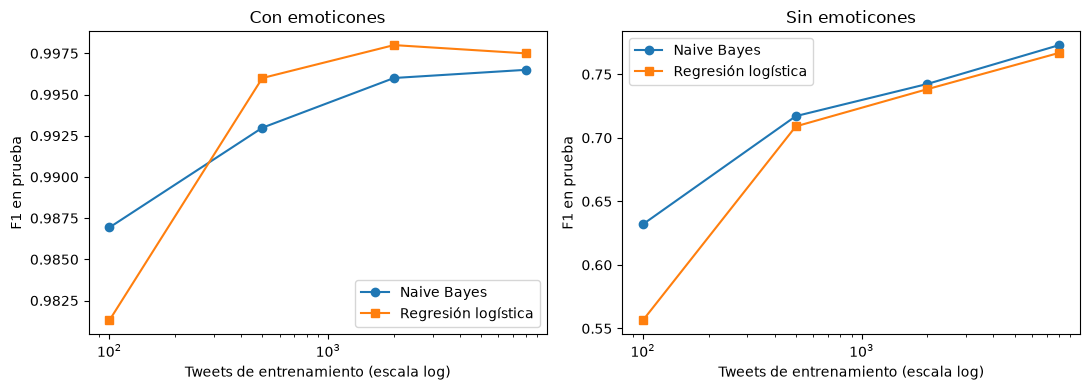

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for ax, emo in zip(axes, ["con emoticones", "sin emoticones"]):
    for nombre, marcador in [("Naive Bayes", "o-"), ("Regresión logística", "s-")]:
        r = resultados[(resultados.datos == emo) & (resultados.modelo == nombre)]
        ax.plot(r.n_train, r.f1, marcador, label=nombre)
    ax.set_xscale("log")
    ax.set_xlabel("Tweets de entrenamiento (escala log)")
    ax.set_ylabel("F1 en prueba")
    ax.set_title(emo.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

Con emoticones ambos modelos son casi perfectos desde los 500 ejemplos. Sin emoticones la diferencia es pequeña, pero Naive Bayes queda igual o por encima en todos los tamaños, y su ventaja es mayor con 100 tweets. Con corpus más grandes y representaciones más ricas (N-gramas, regularización ajustada), la regresión logística suele alcanzarlo y superarlo.

| | Naive Bayes | Regresión logística |
|---|-------------|---------------------|
| Tipo de modelo | Generativo: $P(\mathbf{x} \mid y)\,P(y)$ | Discriminativo: $P(y \mid \mathbf{x})$ |
| Entrenamiento | Contar frecuencias (una pasada) | Optimización iterativa |
| Supuestos | Independencia condicional de las palabras | Frontera de decisión lineal |
| Características correlacionadas | Las cuenta dos veces (sobreconfianza) | Reparte el peso entre ellas |
| Pocos datos | Suele converger más rápido | Necesita más datos y regularización |
| Muchos datos | Suele quedar por debajo | Suele ser mejor |
| Probabilidades | Mal calibradas (muy cercanas a 0 o 1) | Mejor calibradas |

**Limitaciones comunes a ambos** (por usar bolsa de palabras): ignoran el orden, no manejan negaciones (*"not good"*) y no comparten información entre sinónimos (*good* y *great* son dimensiones independientes). En el siguiente cuaderno empezaremos a atacar este último problema representando las palabras y los documentos como **vectores en un espacio** donde la distancia refleja la similitud.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Vajjala, S., Majumder, B., Gupta, A. & Surana, H. (2020). *Practical Natural Language Processing*. O'Reilly Media.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Ng, A. Y. & Jordan, M. I. (2002). On Discriminative vs. Generative Classifiers: A comparison of logistic regression and naive Bayes. *NeurIPS*.